# Precipitation delta per field, 2025 vs 2024, with cubesip

For every field in [data/2025_S33E117.parquet](data/2025_S33E117.parquet) (60,558 field
boundaries in the Western Australia wheatbelt) this notebook computes the difference in
**annual total precipitation** between 2024 and 2025, and maps it as a choropleth.

The data are ERA5 hourly total precipitation (`tp`) from Earth Data Hub. To avoid one
download per field, the requests are addressed by **geohash level-3 cells** (~1.4° × 1.4°,
about 130 km): the fields fall in just two cells, so the whole notebook needs two downloads
of ~3 MB each, cached by the manifest on re-runs. Inside a request the ERA5 0.25° grid is
kept, so fields still see sub-cell variation: each field takes the value of the ERA5 grid
cell it falls in.

Steps:

1. load the fields and find the level-3 geohash cells that cover them;
2. download ERA5 `tp` for 2024–2025, one request per cell;
3. sum the hourly values to annual totals (mm) and take the difference 2025 − 2024;
4. give each field the delta of its ERA5 cell and draw the choropleth.

Run with the `examples` group installed (`uv sync --group examples`) and an Earth Data Hub
token in `cubesip.yaml` (see the README).

In [1]:
import os
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from matplotlib.patches import Rectangle

import cubesip
from cubesip.spatial import find_dims

# cubesip.yaml and data/ are in the repository root; Jupyter starts in the notebook's folder.
if Path.cwd().name == "examples":
    os.chdir(Path.cwd().parent)

# Chart colours (light theme), as in the other examples.
SURFACE = "#fcfcfb"
INK_PRIMARY = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#898781"
AXIS = "#c3c2b7"
ACCENT = "#2a78d6"

YEARS = (2024, 2025)
GEOHASH_PRECISION = 3  # level-3 cells: 1.40625 x 1.40625 degrees
DATASET = "era5/era5-single-levels-atmosphere-v0"
FIELDS_PATH = "examples/data/2025_S33E117.parquet"


## 1. The fields: a GeoParquet of field boundaries

One row per field, the polygon in EPSG:4326, all for the 2025 season over Sentinel-2 tile
S33E117, north-east of Perth. `representative_point` gives a point guaranteed inside each
polygon, used below to address the field by geohash and to sample the ERA5 grid; unlike a
centroid it needs no projected CRS and never leaves the field.

In [2]:
fields = gpd.read_parquet(FIELDS_PATH)
fields["lon"] = fields.geometry.representative_point().x
fields["lat"] = fields.geometry.representative_point().y

west, south, east, north = fields.total_bounds
mid_lat = (south + north) / 2
print(
    f"{len(fields):,} fields (label: {fields['label'].unique().tolist()}), "
    f"CRS EPSG:{fields.crs.to_epsg()}"
)
print(f"extent: lon {west:.3f}..{east:.3f}, lat {south:.3f}..{north:.3f}")
fields.head()


60,558 fields (label: ['field']), CRS EPSG:4326
extent: lon 116.986..118.014, lat -33.012..-31.985


,time,label,confidence_mean,confidence_median,confidence_min,geometry,chunk_id,lon,lat
0,2025-01-01,field,0.517390,0.520757,0.473898,"POLYGON ((117.00045 -32.33827, 117.00045 -32.3...",S33E117,117.000581,-32.343477
1,2025-01-01,field,0.560974,0.560974,0.560974,"POLYGON ((117.00422 -32.33934, 117.00422 -32.3...",S33E117,117.004264,-32.339434
2,2025-01-01,field,0.514074,0.514074,0.492409,"POLYGON ((117.00458 -32.33503, 117.00458 -32.3...",S33E117,117.004309,-32.335796
3,2025-01-01,field,0.539099,0.544314,0.492409,"POLYGON ((117.00745 -32.3247, 117.00745 -32.32...",S33E117,117.003770,-32.331305
4,2025-01-01,field,0.560974,0.560974,0.560974,"POLYGON ((117.0044 -32.33925, 117.0044 -32.339...",S33E117,117.004444,-32.339300


## 2. The level-3 geohash cells that cover the fields

cubesip requests are addressed by a geohash cell. Encoding each field's point at precision 3
gives the cells to download: level 3 spans 1.40625° × 1.40625°, and 60,558 fields fall in
just two cells, `qd5` and `qd7`. One request per cell covers every field — that is the
optimisation, two downloads instead of tens of thousands.

the fields fall in 2 level-3 cells: ['qd5', 'qd7']
  qd5: lon 116.7188..118.1250, lat -33.7500..-32.3438 (1.41 x 1.41 deg), 39,994 fields
  qd7: lon 116.7188..118.1250, lat -32.3438..-30.9375 (1.41 x 1.41 deg), 20,564 fields


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


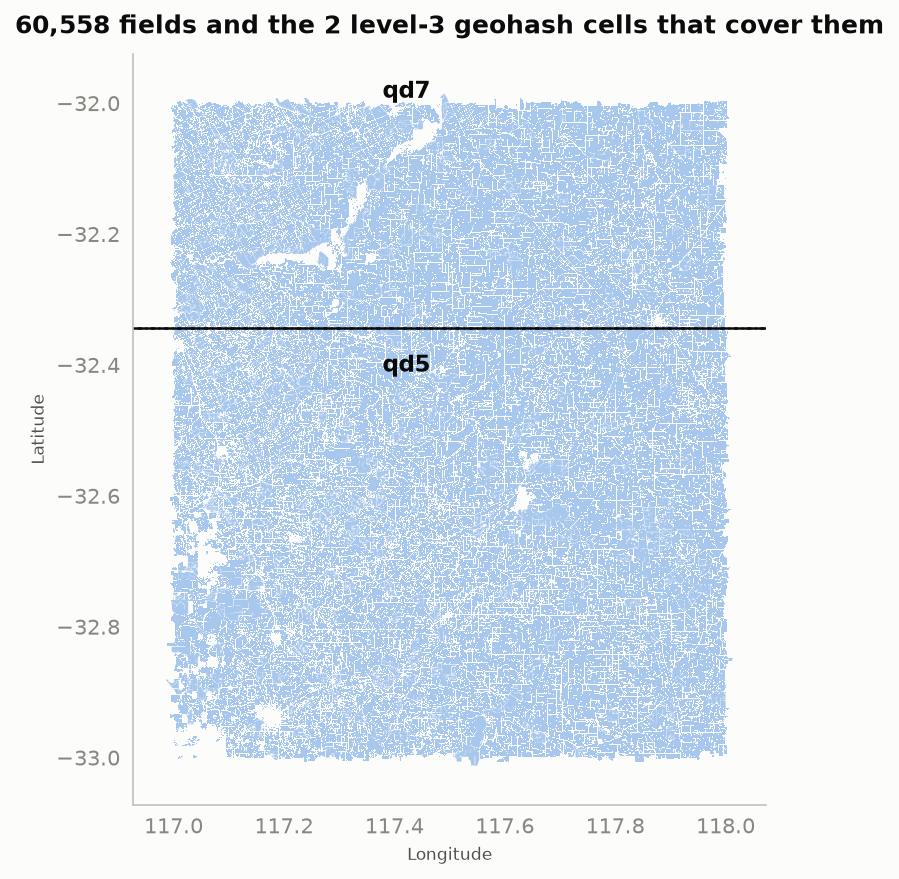

In [3]:
fields["geohash"] = [
    cubesip.geohash.encode(lat=y, lon=x, precision=GEOHASH_PRECISION)
    for x, y in zip(fields["lon"], fields["lat"])
]
cells = sorted(fields["geohash"].unique())
print(f"the fields fall in {len(cells)} level-{GEOHASH_PRECISION} cells: {cells}")
for cell in cells:
    b = cubesip.geohash.bbox(cell)
    n = (fields["geohash"] == cell).sum()
    print(
        f"  {cell}: lon {b.west:.4f}..{b.east:.4f}, lat {b.south:.4f}..{b.north:.4f} "
        f"({b.east - b.west:.2f} x {b.north - b.south:.2f} deg), {n:,} fields"
    )

fig, ax = plt.subplots(figsize=(7, 6.5), dpi=150)
fig.patch.set_facecolor(SURFACE)
ax.set_facecolor(SURFACE)
fields.plot(ax=ax, color=ACCENT, alpha=0.4, linewidth=0)
for cell in cells:
    b = cubesip.geohash.bbox(cell)
    ax.add_patch(
        Rectangle(
            (b.west, b.south),
            b.east - b.west,
            b.north - b.south,
            fill=False,
            edgecolor=INK_PRIMARY,
            linewidth=1.2,
            linestyle="--",
        )
    )
    ax.text(
        (b.west + b.east) / 2,
        min(b.north, north + 0.06) - 0.04,  # keep the label inside the view
        cell,
        ha="center",
        va="top",
        color=INK_PRIMARY,
        fontsize=11,
        fontweight="semibold",
    )
# Show the fields, not the full cells: the rectangles are clipped at the view's edges.
ax.set_xlim(west - 0.06, east + 0.06)
ax.set_ylim(south - 0.06, north + 0.06)
ax.set_aspect(1 / np.cos(np.radians(mid_lat)))  # metres look square
ax.set_xlabel("Longitude", color=INK_SECONDARY)
ax.set_ylabel("Latitude", color=INK_SECONDARY)
ax.tick_params(colors=INK_MUTED, length=0, pad=6)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("bottom", "left"):
    ax.spines[side].set_color(AXIS)
ax.set_title(
    f"{len(fields):,} fields and the {len(cells)} level-{GEOHASH_PRECISION} "
    "geohash cells that cover them",
    color=INK_PRIMARY,
    fontsize=12,
    fontweight="semibold",
    pad=10,
)
plt.show()


## 3. ERA5 total precipitation for 2024 and 2025

One request per cell, the period spanning both years, so each cell is downloaded once.
`check` reports what a request would download without doing it; `run` fetches the data (or
serves them from the manifest cache on a second run). ERA5 `tp` is stored in metres, and the
value at time *t* is the rain of the hour ending at *t*.

In [4]:
period = {"start": f"{YEARS[0]}-01-01", "end": f"{YEARS[1]}-12-31"}
requests = {
    cell: {
        "driver": "edh",
        "dataset": DATASET,
        "variables": ["tp"],
        "geohash": cell,
        "time": period,
        "target_dir": "data",
    }
    for cell in cells
}
for request in requests.values():
    print(cubesip.check(request), end="\n\n")


cubesip check: edh era5/era5-single-levels-atmosphere-v0 [tp] @ qd5, 2024-01-01 to 2025-12-31
  status : cached (geohash qd5) in C:\Users\matte\OneDrive\local\work\cubesip\data\edh_era5-single-levels-atmosphere-v0_qd5_20240101-20251231_4184a2c6.nc

cubesip check: edh era5/era5-single-levels-atmosphere-v0 [tp] @ qd7, 2024-01-01 to 2025-12-31
  status : cached (geohash qd7) in C:\Users\matte\OneDrive\local\work\cubesip\data\edh_era5-single-levels-atmosphere-v0_qd7_20240101-20251231_4184a2c6.nc



In [5]:
datasets = {}
for cell, request in requests.items():
    result = cubesip.run(request)
    origin = "from cache" if result.from_cache else "downloaded"
    print(f"{cell}: {origin}, {result.path.name}")
    datasets[cell] = result.dataset


qd5: from cache, edh_era5-single-levels-atmosphere-v0_qd5_20240101-20251231_4184a2c6.nc


qd7: from cache, edh_era5-single-levels-atmosphere-v0_qd7_20240101-20251231_4184a2c6.nc


## 4. Annual totals and their difference

The hourly values are summed per calendar year and converted from metres to millimetres. The
grouping is off by a single hour at each year boundary — the hour ending at 00:00 on
1 January belongs to the year before — which is negligible for an annual total. The two
cells share one grid row on their common edge; `xr.merge` stitches them, the shared row
holding identical values from the same store.

In [6]:
def annual_mm(ds: xr.Dataset) -> xr.DataArray:
    """Total precipitation per calendar year (mm) for every ERA5 grid cell."""
    dims = find_dims(ds)
    return (ds["tp"] * 1000.0).groupby(f"{dims.time}.year").sum(dims.time)


# join="outer" unions the two latitude axes; compat="no_conflicts" checks the shared row.
yearly = xr.merge(
    [annual_mm(ds) for ds in datasets.values()], join="outer", compat="no_conflicts"
)["tp"]
dims = find_dims(yearly.to_dataset())
totals = yearly.sel(year=list(YEARS))
delta = totals.sel(year=YEARS[1]) - totals.sel(year=YEARS[0])
print(totals)


<xarray.DataArray 'tp' (year: 2, latitude: 12, longitude: 6)> Size: 576B
dask.array<getitem, shape=(2, 12, 6), dtype=float32, chunksize=(1, 6, 6), chunktype=numpy.ndarray>
Coordinates:
  * year       (year) int64 16B 2024 2025
  * latitude   (latitude) float64 96B -33.75 -33.5 -33.25 ... -31.5 -31.25 -31.0
  * longitude  (longitude) float64 48B 116.8 117.0 117.2 117.5 117.8 118.0
Attributes: (12/32)
    GRIB_paramId:                             228
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      1038240
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            accum
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               m
    long_name:                                Total precipitation
    units:                                    m
    standard_name:            

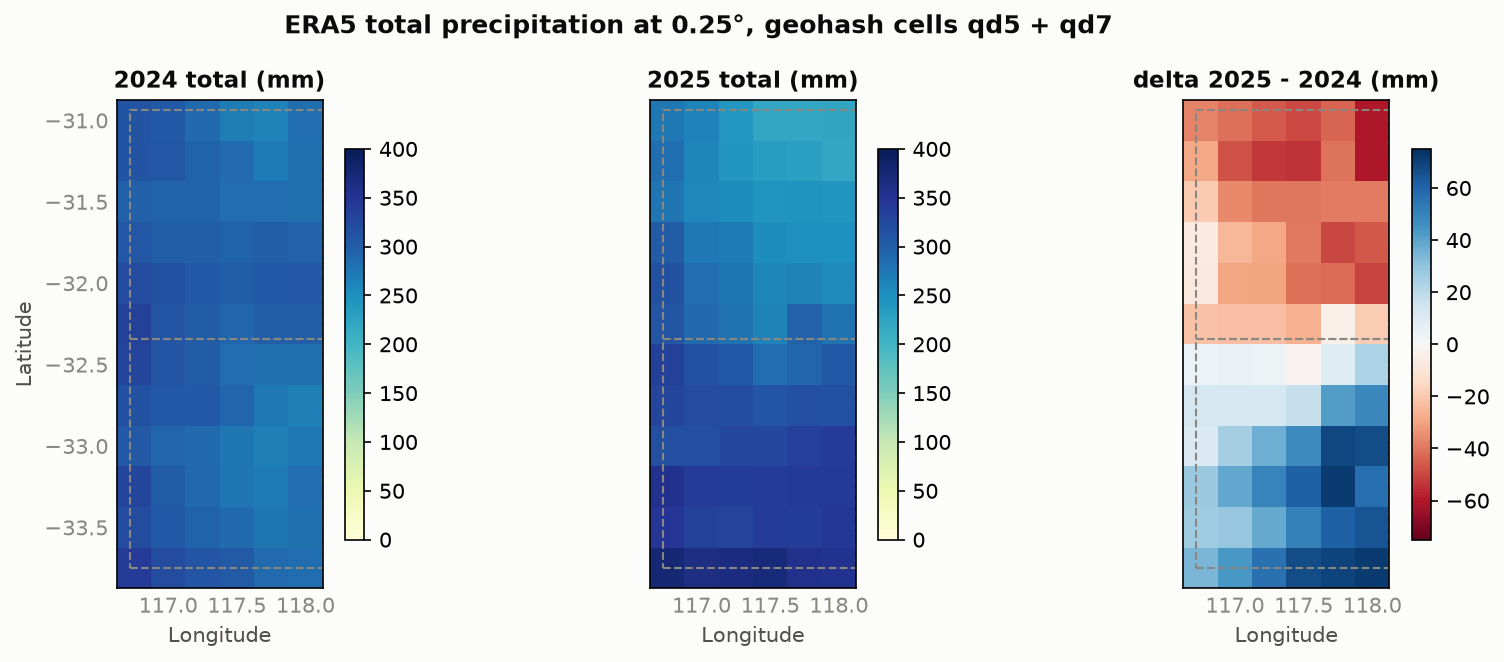

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), dpi=150, sharey=True)
fig.patch.set_facecolor(SURFACE)
top = float(np.ceil(totals.max() / 100) * 100)
lim = float(np.ceil(abs(delta).max() / 25) * 25)
for ax, year in zip(axes[:2], YEARS):
    mesh = ax.pcolormesh(
        totals[dims.x], totals[dims.y], totals.sel(year=year),
        cmap="YlGnBu", vmin=0, vmax=top,
    )
    ax.set_title(f"{year} total (mm)", color=INK_PRIMARY, fontsize=11, fontweight="semibold")
    fig.colorbar(mesh, ax=ax, shrink=0.8)
mesh = axes[2].pcolormesh(
    delta[dims.x], delta[dims.y], delta, cmap="RdBu", vmin=-lim, vmax=lim
)
axes[2].set_title(
    f"delta {YEARS[1]} - {YEARS[0]} (mm)", color=INK_PRIMARY, fontsize=11,
    fontweight="semibold",
)
fig.colorbar(mesh, ax=axes[2], shrink=0.8)
for ax in axes:
    ax.set_facecolor(SURFACE)
    ax.set_aspect(1 / np.cos(np.radians(mid_lat)))
    ax.tick_params(colors=INK_MUTED, length=0, pad=4)
    ax.set_xlabel("Longitude", color=INK_SECONDARY)
    for cell in cells:
        b = cubesip.geohash.bbox(cell)
        ax.add_patch(
            Rectangle(
                (b.west, b.south), b.east - b.west, b.north - b.south,
                fill=False, edgecolor=INK_MUTED, linewidth=1, linestyle="--",
            )
        )
axes[0].set_ylabel("Latitude", color=INK_SECONDARY)
fig.suptitle(
    f"ERA5 total precipitation at 0.25°, geohash cells {' + '.join(cells)}",
    color=INK_PRIMARY,
    fontsize=12,
    fontweight="semibold",
)
fig.subplots_adjust(top=0.85)
plt.show()


## 5. From ERA5 cells to fields

Each field takes the value of the ERA5 cell its point falls in (nearest grid cell;
0.25° ≈ 25 km, much larger than a field). Fields in the same ERA5 cell share the same
delta — that is the resolution of the product.

In [8]:
xs = xr.DataArray(fields["lon"].to_numpy(), dims="field")
ys = xr.DataArray(fields["lat"].to_numpy(), dims="field")
at_fields = totals.sel({dims.x: xs, dims.y: ys}, method="nearest")
for year in YEARS:
    fields[f"tp_{year}_mm"] = at_fields.sel(year=year).to_numpy().round(1)
fields["delta_mm"] = (fields[f"tp_{YEARS[1]}_mm"] - fields[f"tp_{YEARS[0]}_mm"]).round(1)

cols = [f"tp_{YEARS[0]}_mm", f"tp_{YEARS[1]}_mm", "delta_mm"]
print(fields[cols].describe().round(1), "\n")
print(fields.groupby("geohash")[cols].mean().round(1))


       tp_2024_mm  tp_2025_mm  delta_mm
count     60558.0     60558.0   60558.0
mean        294.7       299.0       4.2
std          12.9        20.8      28.0
min         266.0       257.3     -50.8
25%         284.9       281.2     -22.2
50%         299.9       305.6       3.7
75%         307.0       316.2      17.7
max         314.7       341.2      68.3 

         tp_2024_mm  tp_2025_mm   delta_mm
geohash                                   
qd5      290.600006  309.899994  19.299999
qd7      302.899994  277.700012 -25.100000


## 6. Choropleth of the delta

One colour per field: blue marks a wetter 2025 than 2024, red a drier one. The blocky
pattern is the ERA5 grid showing through the field boundaries. The map is saved to `data/`.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


Choropleth: data\fields_precip_delta_2025_minus_2024.png


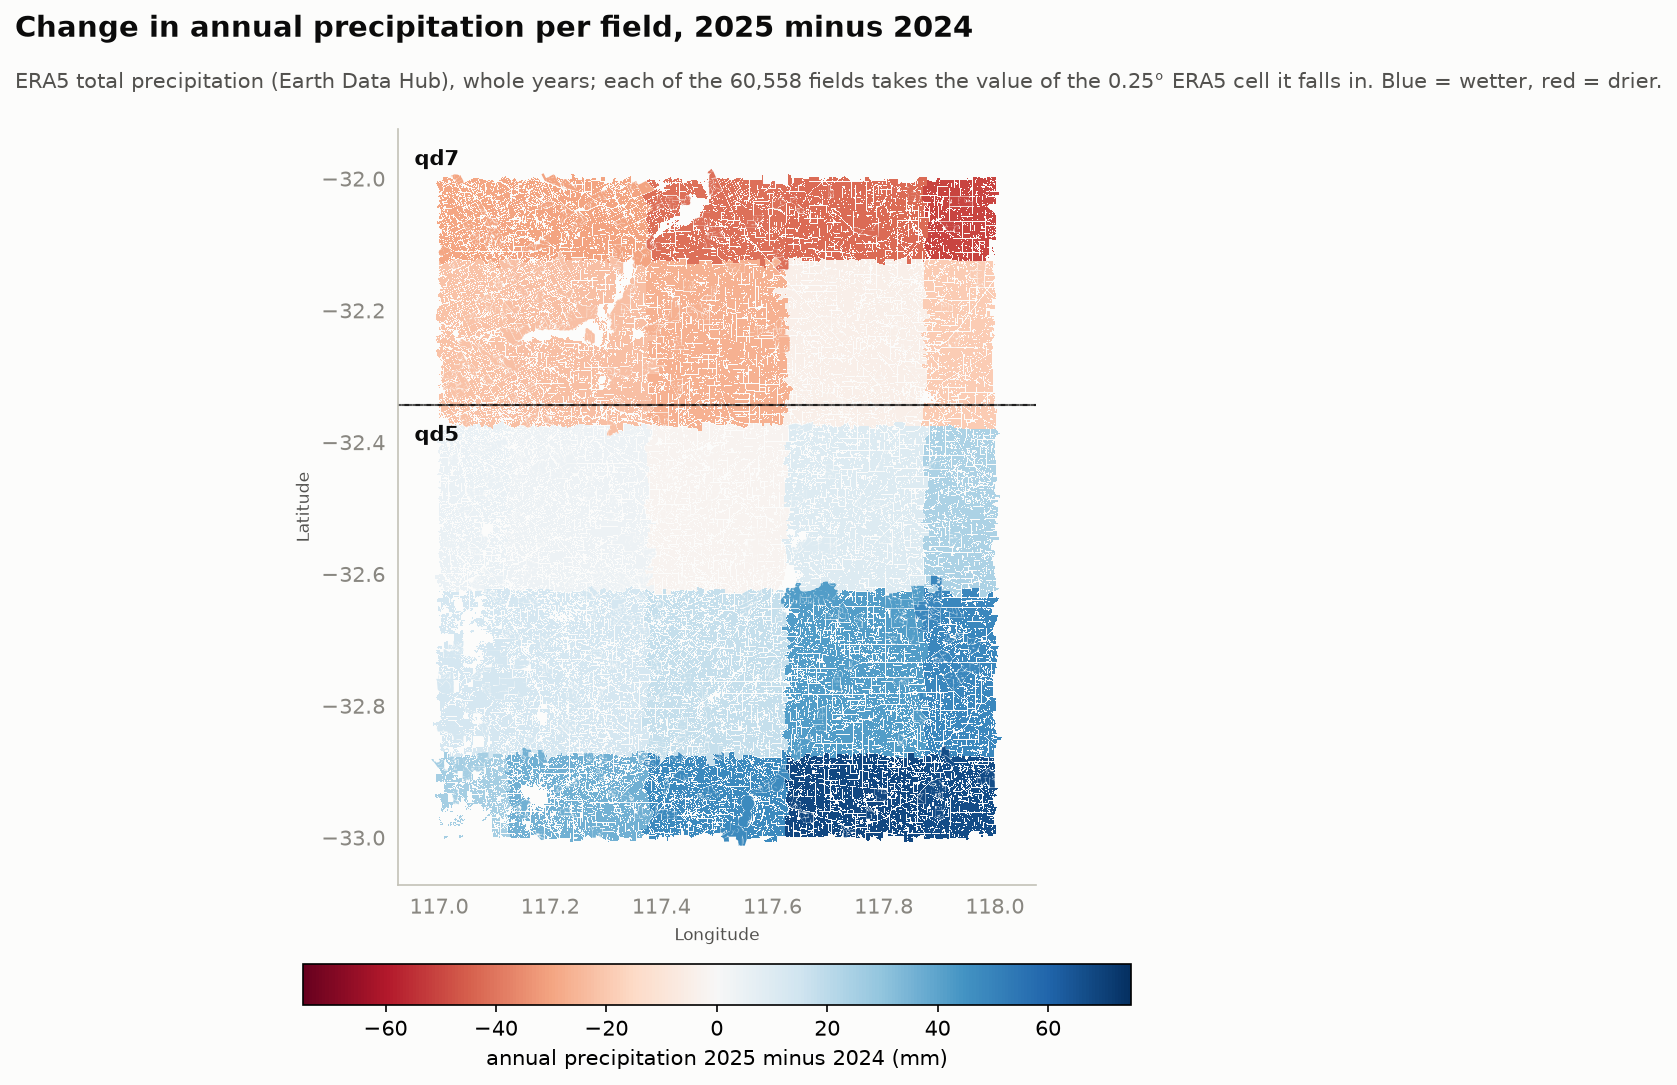

In [9]:
lim = float(np.ceil(abs(fields["delta_mm"]).max() / 25) * 25)
fig, ax = plt.subplots(figsize=(9.5, 8.5), dpi=150)
fig.patch.set_facecolor(SURFACE)
ax.set_facecolor(SURFACE)
fields.plot(
    column="delta_mm",
    ax=ax,
    cmap="RdBu",
    vmin=-lim,
    vmax=lim,
    linewidth=0,
    legend=True,
    legend_kwds={
        "label": f"annual precipitation {YEARS[1]} minus {YEARS[0]} (mm)",
        "orientation": "horizontal",
        "shrink": 0.75,
        "pad": 0.08,
    },
)
for cell in cells:
    b = cubesip.geohash.bbox(cell)
    ax.add_patch(
        Rectangle(
            (b.west, b.south), b.east - b.west, b.north - b.south,
            fill=False, edgecolor=INK_PRIMARY, linewidth=1, linestyle="--", alpha=0.7,
        )
    )
    ax.text(
        max(b.west, west - 0.06) + 0.03,
        min(b.north, north + 0.06) - 0.03,  # keep the label inside the view
        cell,
        ha="left",
        va="top",
        color=INK_PRIMARY,
        fontsize=10,
        fontweight="semibold",
    )
# Show the fields, not the full cells: the rectangles are clipped at the view's edges.
ax.set_xlim(west - 0.06, east + 0.06)
ax.set_ylim(south - 0.06, north + 0.06)
ax.set_aspect(1 / np.cos(np.radians(mid_lat)))
ax.set_xlabel("Longitude", color=INK_SECONDARY)
ax.set_ylabel("Latitude", color=INK_SECONDARY)
ax.tick_params(colors=INK_MUTED, length=0, pad=6)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("bottom", "left"):
    ax.spines[side].set_color(AXIS)
fig.subplots_adjust(top=0.88)
fig.text(
    0.02,
    0.97,
    f"Change in annual precipitation per field, {YEARS[1]} minus {YEARS[0]}",
    va="top",
    color=INK_PRIMARY,
    fontsize=14,
    fontweight="semibold",
)
fig.text(
    0.02,
    0.925,
    f"ERA5 total precipitation (Earth Data Hub), whole years; each of the {len(fields):,} "
    "fields takes the value of the 0.25° ERA5 cell it falls in. Blue = wetter, red = drier.",
    va="top",
    color=INK_SECONDARY,
    fontsize=10,
)
png_path = Path(
    f"data/fields_precip_delta_{YEARS[1]}_minus_{YEARS[0]}.png"
)
fig.savefig(png_path, facecolor=SURFACE, bbox_inches="tight", pad_inches=0.2)
print(f"Choropleth: {png_path}")
plt.show()
